In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")

In [ ]:

possible_files = ["travel_insurance.csv", "travel_insurance", "TravelInsurance.csv"]
data_file = next((f for f in possible_files if os.path.isfile(f)), None)

if data_file is None:
    raise FileNotFoundError(
        "Dataset not found. Put travel_insurance.csv in the same folder as this notebook "
        "or update data_file with the correct path."
    )

df = pd.read_csv('travel_insurance.csv')
print("Dataset loaded:", data_file)
print("Shape:", df.shape)
display(df.head())

Dataset loaded: travel_insurance.csv
Shape: (1987, 9)


,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,31,Government Sector,Yes,400000,6,1,No,No,0
1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0


In [ ]:

df.columns = df.columns.str.strip()
print("Columns:", df.columns.tolist())
print("\\nMissing values before cleaning:")
display(df.isna().sum())
print("\\nDuplicate rows:", df.duplicated().sum())

Columns: ['Age', 'Employment Type', 'GraduateOrNot', 'AnnualIncome', 'FamilyMembers', 'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad', 'TravelInsurance']
\nMissing values before cleaning:


Age                    0
Employment Type        0
GraduateOrNot          0
AnnualIncome           0
FamilyMembers          0
ChronicDiseases        0
FrequentFlyer          0
EverTravelledAbroad    0
TravelInsurance        0
dtype: int64

\nDuplicate rows: 738


In [ ]:

df = df.drop_duplicates().copy()

for col in df.columns:
    if df[col].isna().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            mode = df[col].mode(dropna=True)
            if not mode.empty:
                df[col] = df[col].fillna(mode.iloc[0])

print("Shape after removing duplicates:", df.shape)
print("Missing values after cleaning:")
display(df.isna().sum())

Shape after removing duplicates: (1249, 9)
Missing values after cleaning:


Age                    0
Employment Type        0
GraduateOrNot          0
AnnualIncome           0
FamilyMembers          0
ChronicDiseases        0
FrequentFlyer          0
EverTravelledAbroad    0
TravelInsurance        0
dtype: int64

In [ ]:

yes_no_columns = ["FrequentFlyer", "EverTravelledAbroad", "GraduateOrNot"]
for col in yes_no_columns:
    if col in df.columns:
        df[col] = df[col].replace({
            "Yes": 1, "No": 0, "yes": 1, "no": 0,
            "YES": 1, "NO": 0
        })

# Encode Employment Type if present.
if "Employment Type" in df.columns:
    df["Employment Type"] = df["Employment Type"].replace({
        "Government Sector": 1,
        "Private Sector/Self Employed": 0
    })


target = "TravelInsurance"
if target not in df.columns:
    raise KeyError(f"Target column '{target}' was not found. Check the dataset column names.")

if df[target].dtype == "object":
    df[target] = df[target].replace({"Yes": 1, "No": 0, "yes": 1, "no": 0})


print("Data types after basic encoding:")
display(df.dtypes)

Data types after basic encoding:


Age                    int64
Employment Type        int64
GraduateOrNot          int64
AnnualIncome           int64
FamilyMembers          int64
ChronicDiseases        int64
FrequentFlyer          int64
EverTravelledAbroad    int64
TravelInsurance        int64
dtype: object

In [7]:
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
Age,1249.0,29.755805,2.921039,25.0,28.0,29.0,32.0,35.0
Employment Type,1249.0,0.298639,0.457844,0.0,0.0,0.0,1.0,1.0
GraduateOrNot,1249.0,0.838271,0.368350,0.0,1.0,1.0,1.0,1.0
AnnualIncome,1249.0,934547.638110,360729.284255,300000.0,600000.0,900000.0,1200000.0,1800000.0
FamilyMembers,1249.0,4.890312,1.762313,2.0,4.0,5.0,6.0,9.0
ChronicDiseases,1249.0,0.333066,0.471499,0.0,0.0,0.0,1.0,1.0
FrequentFlyer,1249.0,0.236189,0.424910,0.0,0.0,0.0,0.0,1.0
EverTravelledAbroad,1249.0,0.195356,0.396634,0.0,0.0,0.0,0.0,1.0
TravelInsurance,1249.0,0.386709,0.487191,0.0,0.0,0.0,1.0,1.0


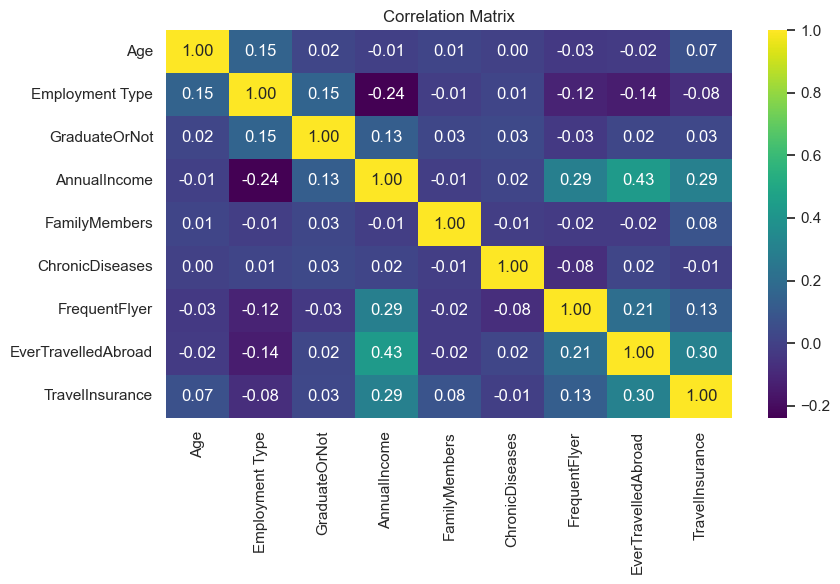

In [8]:
numeric_df = df.select_dtypes(include=[np.number])
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(9, 6))
    sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="viridis")
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

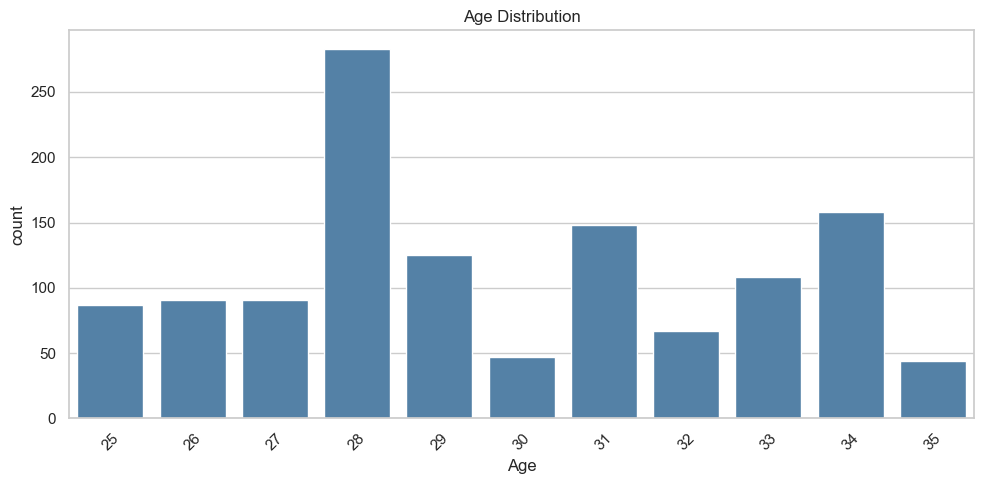

In [9]:
if "Age" in df.columns:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x="Age", order=sorted(df["Age"].dropna().unique()), color="steelblue")
    plt.title("Age Distribution")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

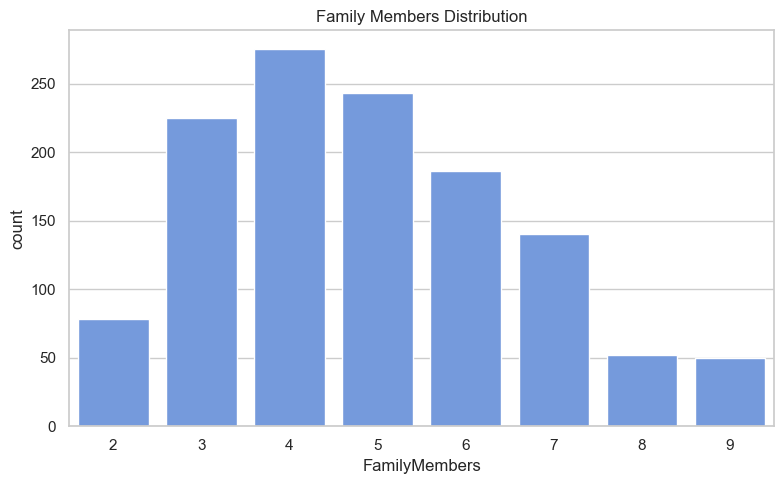

In [10]:
if "FamilyMembers" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x="FamilyMembers", color="cornflowerblue")
    plt.title("Family Members Distribution")
    plt.tight_layout()
    plt.show()

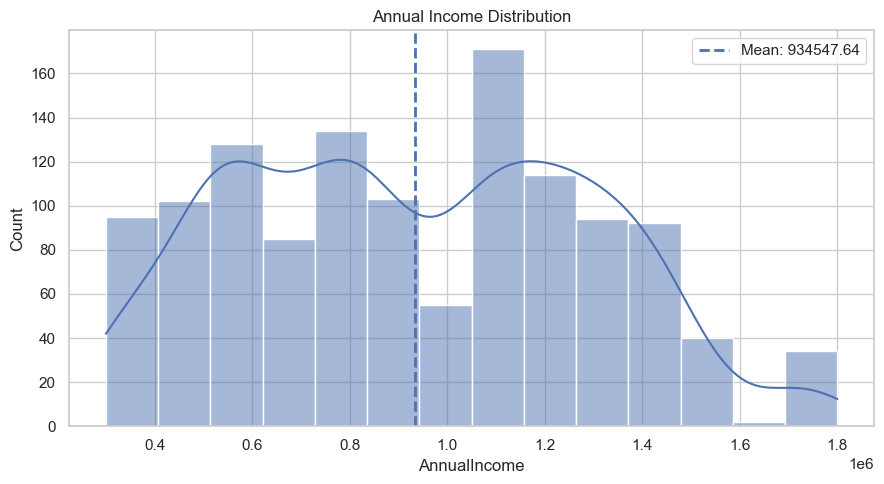

Annual income standard deviation: 360729.28425462754
Annual income minimum: 300000
Annual income maximum: 1800000


In [11]:
if "AnnualIncome" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df["AnnualIncome"], kde=True)
    mean_income = df["AnnualIncome"].mean()
    plt.axvline(mean_income, linestyle="--", linewidth=2, label=f"Mean: {mean_income:.2f}")
    plt.title("Annual Income Distribution")
    plt.legend()
    plt.tight_layout()
    plt.show()
    print("Annual income standard deviation:", df["AnnualIncome"].std())
    print("Annual income minimum:", df["AnnualIncome"].min())
    print("Annual income maximum:", df["AnnualIncome"].max())

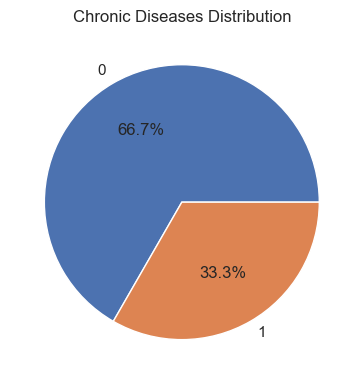

In [12]:
if "ChronicDiseases" in df.columns:
    plt.figure(figsize=(6, 4))
    df["ChronicDiseases"].value_counts().sort_index().plot(kind="pie", autopct="%1.1f%%")
    plt.title("Chronic Diseases Distribution")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

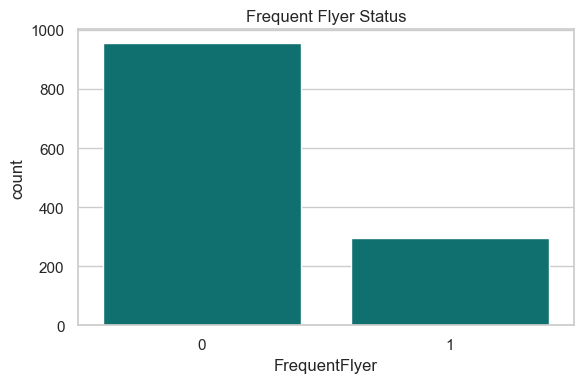

In [13]:
if "FrequentFlyer" in df.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="FrequentFlyer", color="teal")
    plt.title("Frequent Flyer Status")
    plt.tight_layout()
    plt.show()

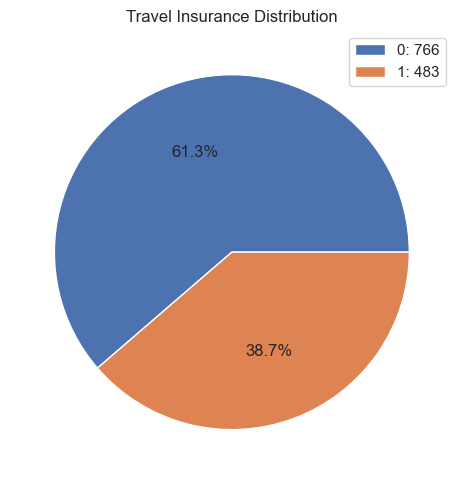

In [14]:
plt.figure(figsize=(6, 5))
df[target].value_counts().sort_index().plot(kind="pie", autopct="%1.1f%%", labels=None)
plt.legend([f"{idx}: {count}" for idx, count in df[target].value_counts().sort_index().items()],
           loc="best")
plt.title("Travel Insurance Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [ ]:

X = df.drop(columns=[target])
y = df[target]

if y.isna().any():
    raise ValueError("The target column contains missing values. Please check the dataset.")

X = pd.get_dummies(X, drop_first=False)
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True)).fillna(0)


if y.dtype == "object":
    y = y.astype("category").cat.codes

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Feature count:", X.shape[1])

Training rows: 999
Testing rows: 250
Feature count: 8


In [16]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

baseline_predictions = rf.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
print(f"Baseline Random Forest accuracy: {baseline_accuracy * 100:.2f}%")

Baseline Random Forest accuracy: 62.40%


In [ ]:

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20],
    "max_features": ["sqrt"],
    "min_samples_leaf": [1, 3],
    "min_samples_split": [2, 8],
    "criterion": ["gini", "entropy"]
}

grid_search_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)
grid_search_rf.fit(X_train, y_train)
print("Best parameters:", grid_search_rf.best_params_)
print(f"Best cross-validation accuracy: {grid_search_rf.best_score_ * 100:.2f}%")

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best parameters: {'criterion': 'entropy', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 8, 'n_estimators': 200}
Best cross-validation accuracy: 75.88%


In [18]:
best_rf = grid_search_rf.best_estimator_
y_pred = best_rf.predict(X_test)

tuned_accuracy = accuracy_score(y_test, y_pred)
print(f"Tuned Random Forest test accuracy: {tuned_accuracy * 100:.2f}%")
print(f"Change from baseline: {(tuned_accuracy - baseline_accuracy) * 100:.2f} percentage points")
print("\\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Tuned Random Forest test accuracy: 72.00%
Change from baseline: 9.60 percentage points
\nClassification Report:
              precision    recall  f1-score   support

           0       0.71      0.92      0.80       153
           1       0.75      0.41      0.53        97

    accuracy                           0.72       250
   macro avg       0.73      0.66      0.67       250
weighted avg       0.73      0.72      0.70       250



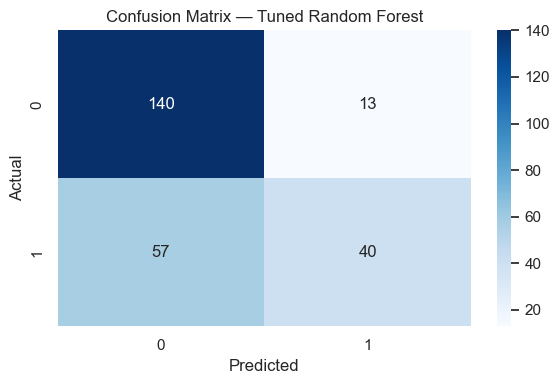

In [19]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix — Tuned Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()